# **1. Perkenalan Dataset**

Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Eksperimen pada repositori ini memakai Statlog (German Credit Data) dari UCI Machine Learning Repository. Dataset ini mengklasifikasikan individu yang dideskripsikan oleh sejumlah atribut sebagai risiko kredit baik (good) atau buruk (bad). Data aslinya disediakan oleh Prof. Hofmann dan berisi atribut kategorikal/simbolik dalam berkas “german.data”. Dataset ini didonasikan pada 16 November 1994.

## **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [2]:
import warnings
import numpy as np
import pandas as pd
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ----- Konstanta -----
RANDOM_STATE = 42
TEST_SIZE = 0.20


SEABORN_DEEP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD",
]


def configure_environment() -> None:
    warnings.filterwarnings("ignore")

    pd.set_option("display.max_columns", 50)
    pd.set_option("display.width", 120)


def report_versions() -> None:
    print("Seluruh pustaka berhasil diimpor.")
    print(f"Versi pandas       : {pd.__version__}")
    print(f"Versi numpy        : {np.__version__}")
    print(f"Versi scikit-learn : {sklearn.__version__}")


configure_environment()
report_versions()

Seluruh pustaka berhasil diimpor.
Versi pandas       : 2.3.3
Versi numpy        : 2.5.4
Versi scikit-learn : 1.9.1


# **3. Memuat Dataset**

In [3]:
COLUMN_NAMES = [
    "checking_status", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_status", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property_type",
    "age_years", "other_installment_plans", "housing", "existing_credits",
    "job", "num_dependents", "telephone", "foreign_worker", "target",
]

def resolve_raw_path(filename="credit_scoring_raw.csv"):
    candidates = [
        Path(filename),
        Path("..") / filename,
        Path("..") / "namadataset_raw" / filename,
        Path("namadataset_raw") / filename,
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(
        f"'{filename}' tidak ditemukan. Lokasi yang dicek: "
        + ", ".join(str(c) for c in candidates)
    )

RAW_PATH = resolve_raw_path()
df = pd.read_csv(RAW_PATH, header=None, names=COLUMN_NAMES)

print(f"Dataset dimuat dari: {RAW_PATH}")
print(f"Dimensi            : {df.shape[0]} baris x {df.shape[1]} kolom")
df.head()


Dataset dimuat dari: ..\credit_scoring_raw.csv
Dimensi            : 1000 baris x 21 kolom


,checking_status,duration_months,credit_history,purpose,credit_amount,savings_status,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property_type,age_years,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [4]:
# -------- Struktur & tipe data --------
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_status          1000 non-null   object
 1   duration_months          1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings_status           1000 non-null   object
 6   employment_since         1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property_type            1000 non-null   object
 12  age_years                1000 non-null   int64 
 13  other_installment_plans  1000 non-null   object
 14  housing                  1000 non-null   

# **4. Exploratory Data Analysis (EDA)**


Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.



In [5]:
# -------- Kualitas data: nilai kosong & duplikat --------
missing = df.isna().sum()
print("Total nilai kosong :", int(missing.sum()))
print("Total baris duplikat:", int(df.duplicated().sum()))

# ----- Statistik deskriptif -----
df.describe().T


Total nilai kosong : 0
Total baris duplikat: 0


,count,mean,std,min,25%,50%,75%,max
duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age_years,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
target,1000.0,1.300,0.458487,1.0,1.0,1.0,2.00,2.0


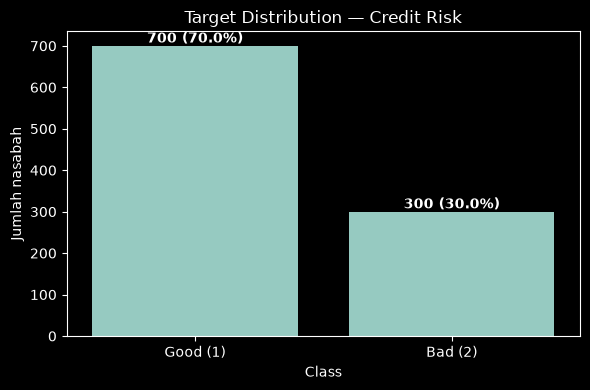

In [6]:
# -------- Distribusi target -------
target_label = df["target"].map({1: "Good (1)", 2: "Bad (2)"})
counts = target_label.value_counts()
pct = (counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
for i, (n, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, n + 8, f"{n} ({p}%)", ha="center", fontweight="bold")
ax.set_title("Target Distribution — Credit Risk")
ax.set_xlabel("Class"); ax.set_ylabel("Jumlah nasabah")
plt.tight_layout(); plt.show()

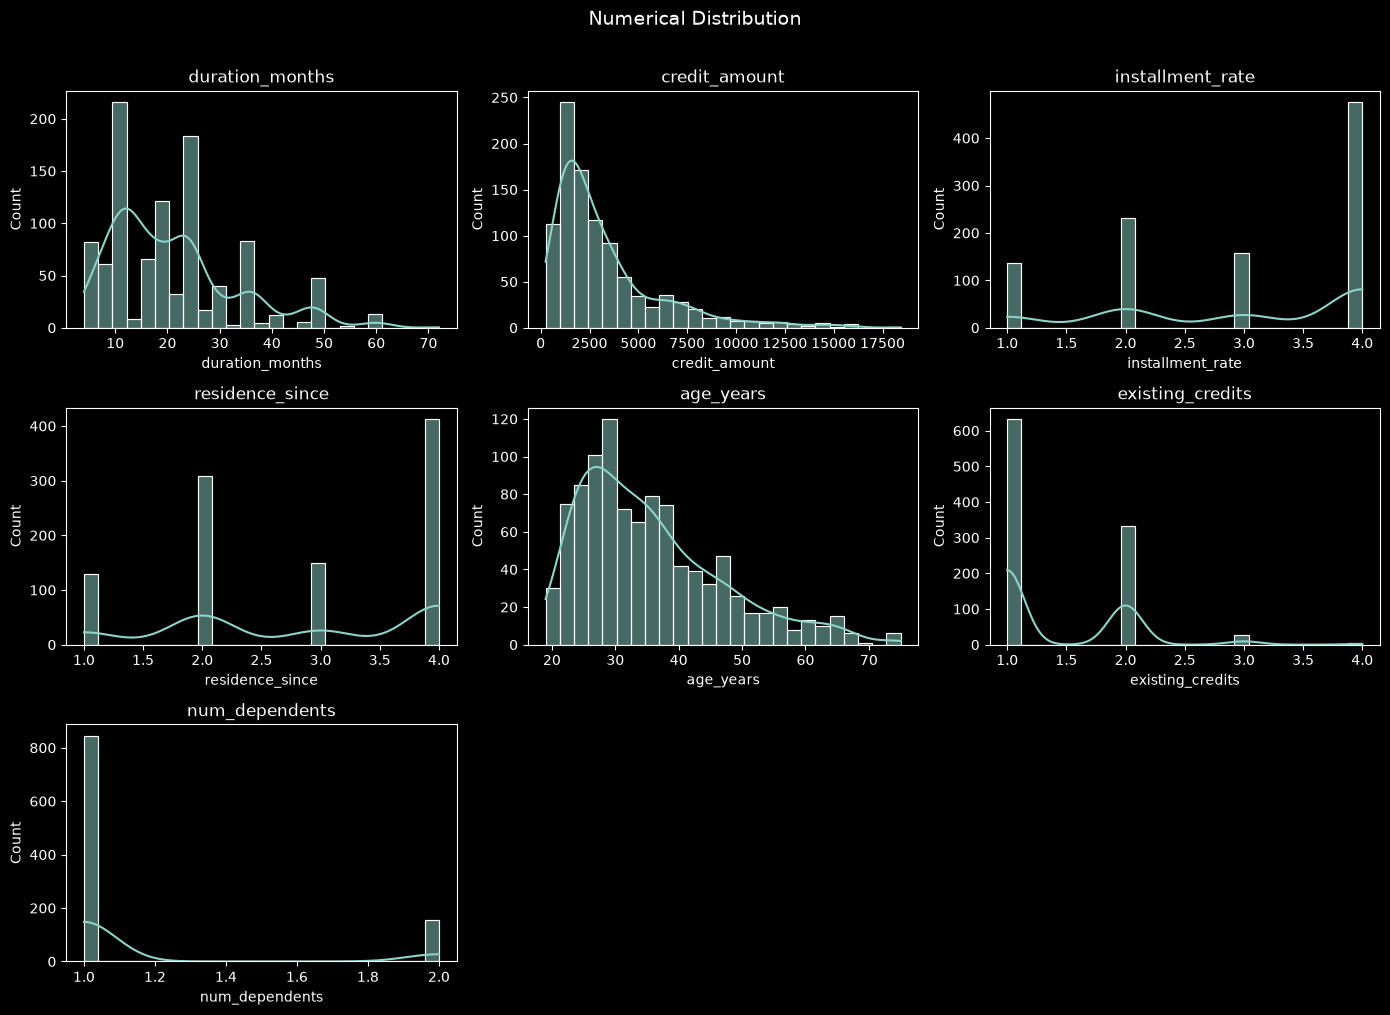

In [7]:
# ------ Distribusi -------
NUMERIC = ["duration_months", "credit_amount", "installment_rate",
           "residence_since", "age_years", "existing_credits", "num_dependents"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(df[col], kde=True, ax=ax, bins=25)
    ax.set_title(col)
for ax in axes.ravel()[len(NUMERIC):]:
    ax.set_visible(False)
plt.suptitle("Numerical Distribution", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()


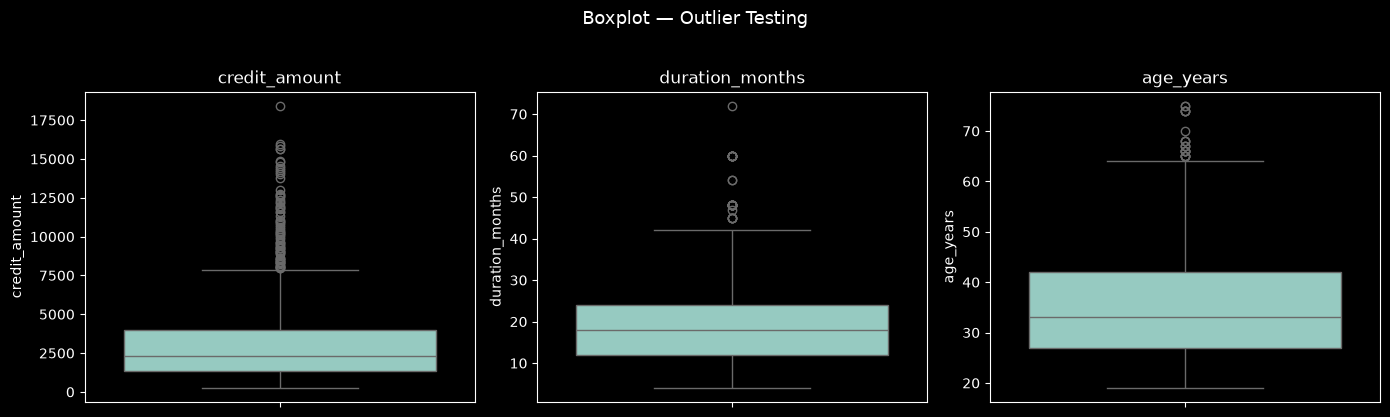

In [8]:
# ----- Deteksi Outlier -----
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["credit_amount", "duration_months", "age_years"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplot — Outlier Testing", y=1.03, fontsize=13)
plt.tight_layout(); plt.show()


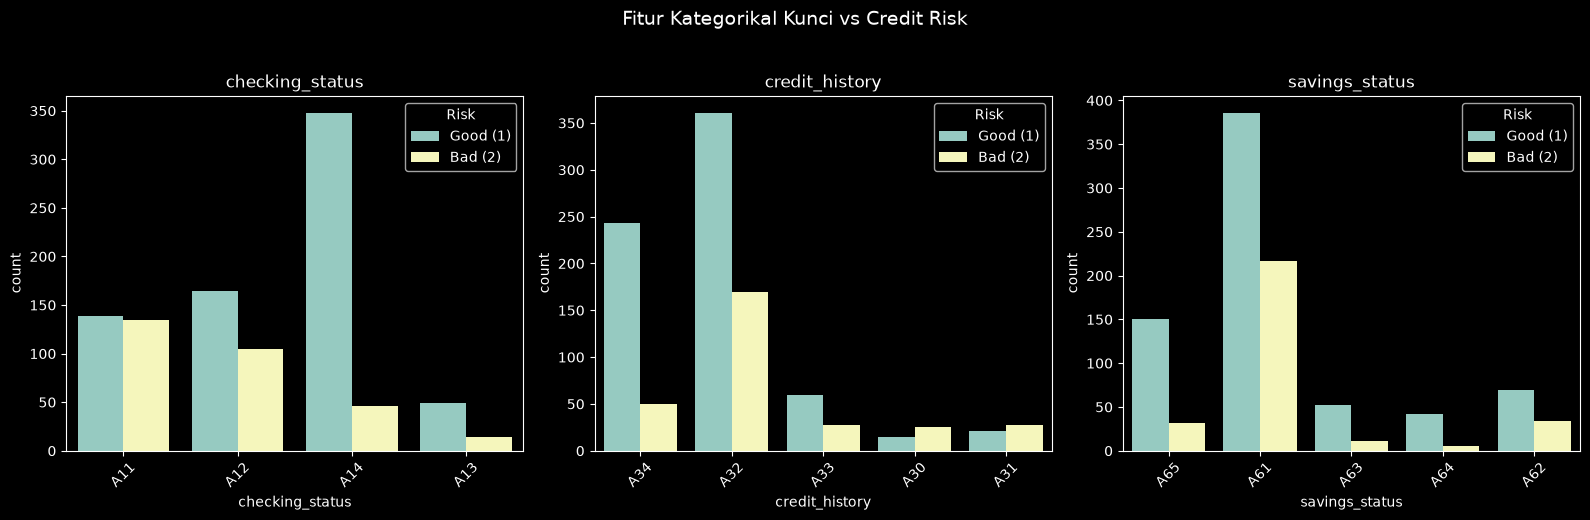

In [9]:
# ─--- Relasi fitur  -----
key_cats = ["checking_status", "credit_history", "savings_status"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, key_cats):
    sns.countplot(data=df.assign(Risk=target_label),
                  x=col, hue="Risk", ax=ax)
    ax.set_title(col); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Fitur Kategorikal Kunci vs Credit Risk", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()


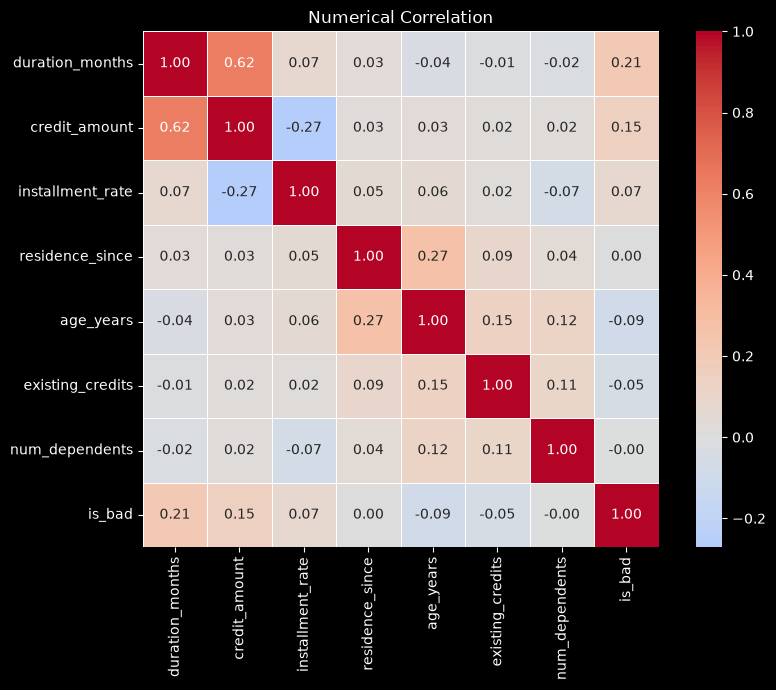

In [10]:
# ---- Matriks korelasi ----
corr_df = df[NUMERIC].copy()
corr_df["is_bad"] = (df["target"] == 2).astype(int)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=.5, ax=ax)
ax.set_title("Numerical Correlation")
plt.tight_layout(); plt.show()


# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.



In [11]:
# ---- Pemetaan target ke credit risk ----
data = df.copy()
data["credit_risk"] = data["target"].map({1: 0, 2: 1})
data = data.drop(columns=["target"])

print("Credit Risk Distribution (0=good, 1=bad):")
print(data["credit_risk"].value_counts().sort_index().to_dict())


Credit Risk Distribution (0=good, 1=bad):
{0: 700, 1: 300}


In [12]:
# ---- Penanganan missing value & duplikat ----
before = len(data)
data = data.drop_duplicates().reset_index(drop=True)
print(f"Baris duplikat dihapus : {before - len(data)}")

assert data.isna().sum().sum() == 0, "Masih terdapat nilai kosong!"
print("Nilai kosong tersisa   :", int(data.isna().sum().sum()))


Baris duplikat dihapus : 0
Nilai kosong tersisa   : 0


In [13]:
# ---- Pemisahan fitur/target & penetapan tipe kolom ----
TARGET = "credit_risk"
categorical_cols = data.select_dtypes(include="object").columns.tolist()
numeric_cols = [c for c in NUMERIC if c in data.columns]

X = data.drop(columns=[TARGET])
y = data[TARGET]

print(f"Fitur numerik    ({len(numeric_cols)}): {numeric_cols}")
print(f"Fitur kategorikal ({len(categorical_cols)}): {categorical_cols}")
print(f"X: {X.shape} | y: {y.shape}")


Fitur numerik    (7): ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age_years', 'existing_credits', 'num_dependents']
Fitur kategorikal (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment_since', 'personal_status_sex', 'other_debtors', 'property_type', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']
X: (1000, 20) | y: (1000,)


In [14]:
# ---- Pemisahan data terstratifikasi ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Set latih : {X_train.shape[0]} baris")
print(f"Set uji   : {X_test.shape[0]} baris")
print("Proporsi bad — latih: {:.3f} | uji: {:.3f}".format(
    y_train.mean(), y_test.mean()))


Set latih : 800 baris
Set uji   : 200 baris
Proporsi bad — latih: 0.300 | uji: 0.300


In [15]:
# ---- Standardisasi + One-Hot Encoding ----
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# fit HANYA pada set latih, lalu transform kedua set
X_train_arr = preprocessor.fit_transform(X_train)
X_test_arr = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_prep = pd.DataFrame(X_train_arr, columns=feature_names, index=X_train.index)
X_test_prep = pd.DataFrame(X_test_arr, columns=feature_names, index=X_test.index)

print(f"Jumlah fitur setelah encoding: {X_train_prep.shape[1]} "
      f"(dari {X_train.shape[1]} fitur asli)")
X_train_prep.head()


Jumlah fitur setelah encoding: 61 (dari 20 fitur asli)


,duration_months,credit_amount,installment_rate,residence_since,age_years,existing_credits,num_dependents,checking_status_A11,checking_status_A12,checking_status_A13,checking_status_A14,credit_history_A30,credit_history_A31,credit_history_A32,credit_history_A33,credit_history_A34,purpose_A40,purpose_A41,purpose_A410,purpose_A42,purpose_A43,purpose_A44,purpose_A45,purpose_A46,purpose_A48,...,personal_status_sex_A91,personal_status_sex_A92,personal_status_sex_A93,personal_status_sex_A94,other_debtors_A101,other_debtors_A102,other_debtors_A103,property_type_A121,property_type_A122,property_type_A123,property_type_A124,other_installment_plans_A141,other_installment_plans_A142,other_installment_plans_A143,housing_A151,housing_A152,housing_A153,job_A171,job_A172,job_A173,job_A174,telephone_A191,telephone_A192,foreign_worker_A201,foreign_worker_A202
828,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
997,-0.742595,-0.892853,0.942164,1.053413,0.242449,-0.718745,-0.436436,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
148,1.289592,0.816433,0.052281,-0.747293,-0.663479,1.045047,-0.436436,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
735,1.289592,0.299568,0.052281,-0.747293,-0.572886,-0.718745,-0.436436,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
130,2.305686,1.982655,-1.727486,-0.747293,-1.025850,-0.718745,-0.436436,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [16]:
# ---- Rakit data train ready & simpan ----
train_ready = X_train_prep.copy()
train_ready[TARGET] = y_train.values
test_ready = X_test_prep.copy()
test_ready[TARGET] = y_test.values

OUT_DIR = Path("credit_scoring_preprocessing")
OUT_DIR.mkdir(exist_ok=True)
train_ready.to_csv(OUT_DIR / "train.csv", index=False)
test_ready.to_csv(OUT_DIR / "test.csv", index=False)

# Validasi akhir data siap latih
assert train_ready.isna().sum().sum() == 0
assert test_ready.isna().sum().sum() == 0
print("Artefak preprocessing tersimpan di:", OUT_DIR.resolve())
print(f"  • train.csv : {train_ready.shape[0]} baris x {train_ready.shape[1]} kolom")
print(f"  • test.csv  : {test_ready.shape[0]} baris x {test_ready.shape[1]} kolom")
print("Validasi: tidak ada nilai kosong pada data siap latih.")
train_ready.head()


Artefak preprocessing tersimpan di: C:\Users\user\Downloads\SMSML_Hartanto Dewantoro\Eksperimen_SML_Hartanto\preprocessing\credit_scoring_preprocessing
  • train.csv : 800 baris x 62 kolom
  • test.csv  : 200 baris x 62 kolom
Validasi: tidak ada nilai kosong pada data siap latih.


,duration_months,credit_amount,installment_rate,residence_since,age_years,existing_credits,num_dependents,checking_status_A11,checking_status_A12,checking_status_A13,checking_status_A14,credit_history_A30,credit_history_A31,credit_history_A32,credit_history_A33,credit_history_A34,purpose_A40,purpose_A41,purpose_A410,purpose_A42,purpose_A43,purpose_A44,purpose_A45,purpose_A46,purpose_A48,...,personal_status_sex_A92,personal_status_sex_A93,personal_status_sex_A94,other_debtors_A101,other_debtors_A102,other_debtors_A103,property_type_A121,property_type_A122,property_type_A123,property_type_A124,other_installment_plans_A141,other_installment_plans_A142,other_installment_plans_A143,housing_A151,housing_A152,housing_A153,job_A171,job_A172,job_A173,job_A174,telephone_A191,telephone_A192,foreign_worker_A201,foreign_worker_A202,credit_risk
828,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1
997,-0.742595,-0.892853,0.942164,1.053413,0.242449,-0.718745,-0.436436,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0
148,1.289592,0.816433,0.052281,-0.747293,-0.663479,1.045047,-0.436436,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0
735,1.289592,0.299568,0.052281,-0.747293,-0.572886,-0.718745,-0.436436,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0
130,2.305686,1.982655,-1.727486,-0.747293,-1.025850,-0.718745,-0.436436,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0


---
## Ringkasan

**Rencana konversi (di luar cakupan notebook ini):**
- **Skilled** — mengonversi langkah §5 menjadi `automate_Nama-siswa.py`: satu fungsi
  preprocessing yang mereplikasi tahapan identik dan mengembalikan data siap latih.
- **Advance** — memicu `automate_Nama-siswa.py` melalui **GitHub Actions** setiap
  kali *trigger* terpantik, menghasilkan dataset terproses terbaru secara otomatis.
